<h1>Goals 2025</h1>

In [21]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')  # All positions
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')  # Partial 2025

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.5
    if partial_goals > row['Expected_npxG']:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.5)
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Gls', 'Expected_npxG', 'predicted_goals_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation (Ensemble only)
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"\nMAE on Partial 2025 Data (All Players): {mae_ensemble:.2f}")

# MAE by Position
print("\nMAE by Position (Partial 2025 Data):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_goals_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005459 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27796
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 169
[LightGBM] [Info] Start training from score 1.952522
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [2]:
# Extract feature importances from individual models
importances = {}
for name, model in models.items():
    if name == 'RF':
        importances[name] = model.named_steps['RF'].feature_importances_
    elif name == 'XGBoost':
        importances[name] = model.named_steps['XGBoost'].feature_importances_
    elif name == 'LightGBM':
        importances[name] = model.named_steps['LightGBM'].feature_importances_

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({
    'Feature': X_features.columns
})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Sort by ensemble importance
feature_importance = feature_importance.sort_values('Ensemble_Importance', ascending=False)

# Print for reference
print(feature_importance)

# Save to CSV for presentation
feature_importance.to_csv('ensemble_feature_importances.csv', index=False)

                Feature  RF_Importance  XGBoost_Importance  \
161      Recent_xG_Form       0.419102            0.058830   
166                 Age       0.188182            0.042477   
51          Medium_Cmp%       0.078616            0.026878   
48           Short_Cmp%       0.003982            0.002729   
21    Per 90 Minutes_xG       0.002514            0.003781   
..                  ...            ...                 ...   
64                  Att       0.000090            0.000000   
76         Outcomes_Cmp       0.000083            0.000000   
56                  xAG       0.000055            0.000000   
37       Standard_PKatt       0.000004            0.000000   
90   GCA Types_PassDead       0.000000            0.000000   

     LightGBM_Importance  Ensemble_Importance  
161                  220            66.185290  
166                  144            43.288016  
51                    94            28.239510  
48                    76            22.802411  
21             

In [22]:
# Extract feature importances from individual models
importances = {}
for name, model in models.items():
    if name == 'RF':
        raw_importance = model.named_steps['RF'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'XGBoost':
        raw_importance = model.named_steps['XGBoost'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'LightGBM':
        raw_importance = model.named_steps['LightGBM'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({
    'Feature': X_features.columns
})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Normalize Ensemble_Importance to sum to 1
total_ensemble_importance = feature_importance['Ensemble_Importance'].sum()
feature_importance['Ensemble_Importance'] = feature_importance['Ensemble_Importance'] / total_ensemble_importance

# Sort by ensemble importance and get top 10
top_10_features = feature_importance.sort_values('Ensemble_Importance', ascending=False).head(10)

# Print top 10 features
#print("\nTop 10 Features with Normalized Ensemble Importance:")
top_10_features[['Feature', 'Ensemble_Importance']]

# Optional: Save to CSV for presentation
#top_10_features[['Feature', 'Ensemble_Importance']].to_csv('top_10_feature_importances.csv', index=False)


,Feature,Ensemble_Importance
161,Recent_xG_Form,0.205363
166,Age,0.101155
51,Medium_Cmp%,0.048086
10,Expected_npxG,0.030852
162,Adjusted_Goal_Rate,0.027709
28,Standard_SoT,0.024259
9,Expected_xG,0.019640
116,Touches_Att Pen,0.016510
136,Starts_Mn/Start,0.011755
12,Expected_npxG+xAG,0.011671


C:\Users\daboo\AppData\Local\Temp\ipykernel_23572\693844314.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')


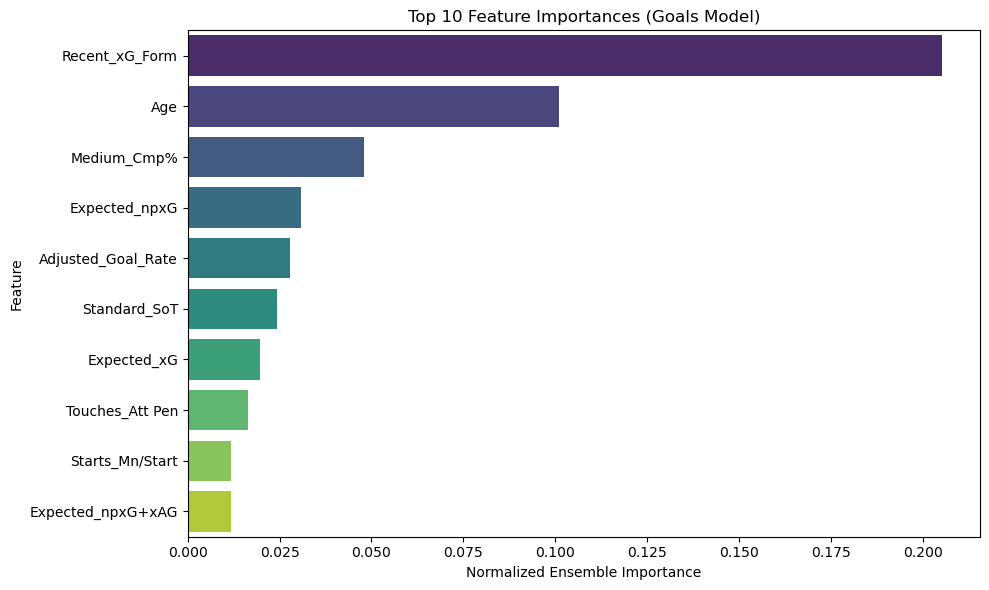

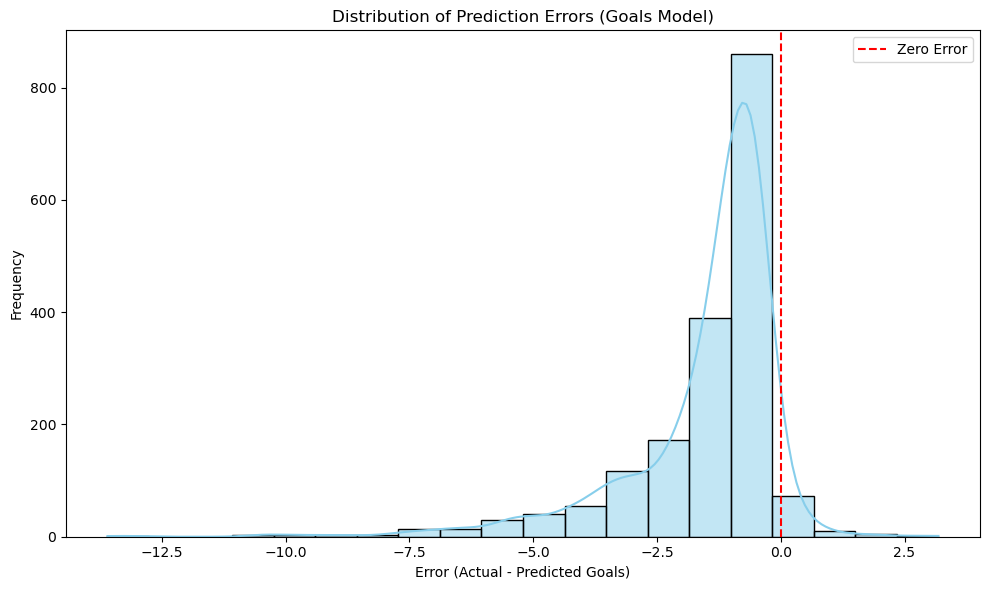

Goals Model MAE on 2025 Data: 1.54


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Assuming the Goals model code is run up to the ensemble prediction section
# Extract feature importances from individual models
importances = {}
for name, model in models.items():
    if name == 'RF':
        raw_importance = model.named_steps['RF'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'XGBoost':
        raw_importance = model.named_steps['XGBoost'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'LightGBM':
        raw_importance = model.named_steps['LightGBM'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({'Feature': X_features.columns})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Normalize Ensemble_Importance to sum to 1
total_ensemble_importance = feature_importance['Ensemble_Importance'].sum()
feature_importance['Ensemble_Importance'] = feature_importance['Ensemble_Importance'] / total_ensemble_importance

# Top 10 Feature Importances Visualization
top_10_features = feature_importance.sort_values('Ensemble_Importance', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Feature Importances (Goals Model)')
plt.xlabel('Normalized Ensemble Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('goals_feature_importances.png')  # Save for presentation slide 11
plt.show()

# Error Visualization (MAE Distribution)
# Assuming validation data from the code (actual vs. predicted for 2025)
pred_2025_df = data_full[data_full['season'] == 2024].set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
errors = actual_vals_ensemble - ensemble_pred_vals

plt.figure(figsize=(10, 6))
sns.histplot(errors, bins=20, kde=True, color='skyblue')
plt.title('Distribution of Prediction Errors (Goals Model)')
plt.xlabel('Error (Actual - Predicted Goals)')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--', label='Zero Error')
plt.legend()
plt.tight_layout()
plt.savefig('goals_error_distribution.png')  # Save for presentation
plt.show()

# Print MAE for reference
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"Goals Model MAE on 2025 Data: {mae_ensemble:.2f}")

<h1>Goals 2024</h1>

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data (all positions)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')

# Add position dummies
data_full['is_FW'] = data_full['pos'].str.contains('FW', na=False).astype(int)
data_full['is_MF'] = data_full['pos'].str.contains('MF', na=False).astype(int)
data_full['is_DF'] = data_full['pos'].str.contains('DF', na=False).astype(int)

# Sort by player and season for lagging
data_full = data_full.sort_values(['player', 'season'])

# Create lagged target (next season's goals)
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering (using current season data to predict next season)
# Old model features
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))
data_full['Goals_Delta'] = data_full.groupby('player')['Performance_Gls'].diff().fillna(0)
data_full['Goals_Delta'] = data_full.groupby('player')['Goals_Delta'].transform('mean').fillna(0)

# New model features
data_full['Gls_per_90'] = data_full['Performance_Gls'] / data_full['90s'].replace(0, 1)
data_full['Gls_per_90_trend'] = data_full.groupby('player')['Gls_per_90'].pct_change().fillna(0)
data_full['Minutes_per_90'] = data_full['Playing Time_Min'] / 90
data_full['Minutes_per_90_trend'] = data_full.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
data_full['Breakout_Signal'] = data_full['Gls_per_90_trend'] * data_full['Minutes_per_90_trend'] * data_full['Team Success_onG']
data_full.loc[data_full['season'] == 2023, 'Gls_per_90_trend'] *= 2.0
data_full.loc[data_full['season'] == 2023, 'Breakout_Signal'] *= 10.0

# General features
data_full['Age'] = 2024 - data_full['born']  # Age as of 2024
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)

# Handle missing values
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(data_full.median(numeric_only=True), inplace=True)

# Drop irrelevant features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define feature set (exclude current-season goals and metadata)
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Debug: Ensure Performance_Gls is not in X_features
if 'Performance_Gls' in X_features.columns:
    raise ValueError("Performance_Gls is still in X_features!")

# Split data: Train on 2019–2022, Test on 2023 to predict 2024
train_data = data_full[data_full['season'].isin([2019, 2020, 2021, 2022])].dropna(subset=['Performance_Gls_next'] + list(X_features.columns))
test_data = data_full[data_full['season'] == 2023].dropna(subset=['Performance_Gls_next'] + list(X_features.columns))

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Weighted training (similar to old model, adjusted for years)
train_weighted_parts = [
    train_data[train_data['season'].isin([2019, 2020])],
    train_data[train_data['season'] == 2021].sample(frac=2, replace=True, random_state=42) if not train_data[train_data['season'] == 2021].empty else pd.DataFrame(),
    train_data[train_data['season'] == 2022].sample(frac=2, replace=True, random_state=42) if not train_data[train_data['season'] == 2022].empty else pd.DataFrame()
]
train_weighted = pd.concat(train_weighted_parts, ignore_index=True)

X_train_weighted = train_weighted[X_features.columns]
y_train_weighted = train_weighted['Performance_Gls_next']

# Models (from new model)
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Cross-validation (from new model)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train_weighted):
    X_tr, X_val = X_train_weighted.iloc[train_idx], X_train_weighted.iloc[val_idx]
    y_tr, y_val = y_train_weighted.iloc[train_idx], y_train_weighted.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train_weighted, y_train_weighted)

# Predict on 2024 test set (using 2023 data)
individual_preds = {name: np.maximum(model.predict(X_test), 0) for name, model in models.items()}

# Ensemble (weights from new model)
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
ensemble_pred = np.maximum(ensemble_pred, 0)

# Calculate MAE and R-squared for 2024
mae_2024 = mean_absolute_error(y_test, ensemble_pred)
r2_2024 = r2_score(y_test, ensemble_pred)

# Print results
print("\nGoal Model (2024 Full Season) - Ensemble Results:")
print(f"MAE: {mae_2024:.2f}")
print(f"R²: {r2_2024:.2f}")

# Results table for inspection
results_2024 = test_data[['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 'Performance_Gls', 'Performance_Gls_next']].copy()
results_2024['predicted_goals_2024'] = ensemble_pred
print("\n2024 Full-Season Predictions (Sample):")
print(results_2024.sort_values('Performance_Gls_next', ascending=False).head(10))

# MAE and R² by Position (2024 Test Set)
print("\nMAE and R² by Position (2024 Test Set):")
for pos in ['FW', 'MF', 'DF']:
    pos_mask = results_2024[f'is_{pos}'] == 1
    if pos_mask.sum() > 0:
        actual_pos = results_2024[pos_mask]['Performance_Gls_next']
        pred_pos = results_2024[pos_mask]['predicted_goals_2024']
        mae_pos = mean_absolute_error(actual_pos, pred_pos)
        r2_pos = r2_score(actual_pos, pred_pos)
        print(f"{pos} - MAE: {mae_pos:.2f}, R²: {r2_pos:.2f}, n={pos_mask.sum()}")

ImportError: DLL load failed while importing _multiarray_umath: The specified module could not be found.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006369 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23237
[LightGBM] [Info] Number of data points in the train set: 8775, number of used features: 170
[LightGBM] [Info] Start training from score 1.869744
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

C:\Users\daboo\AppData\Local\Temp\ipykernel_18768\568794777.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')


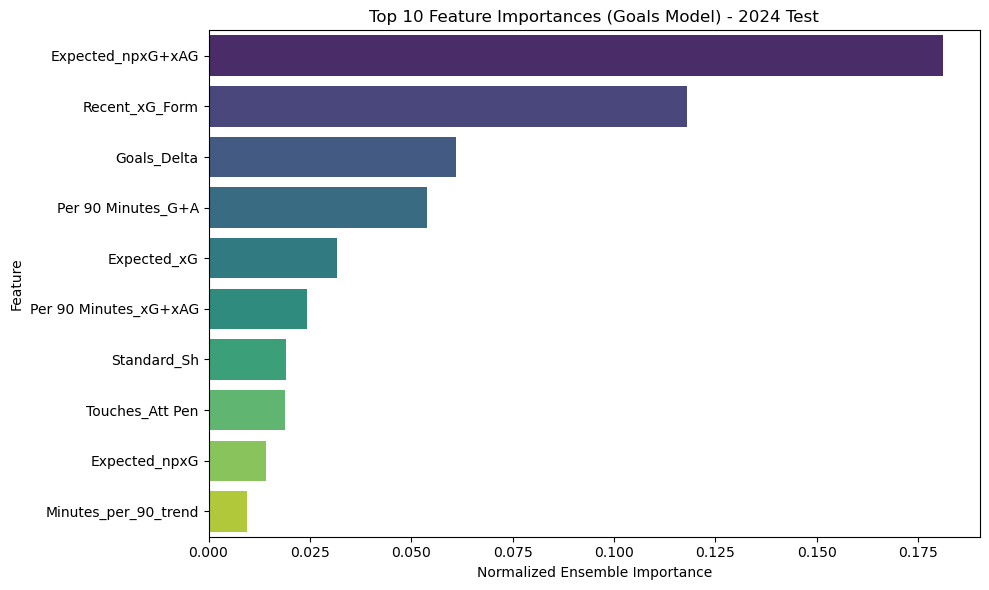

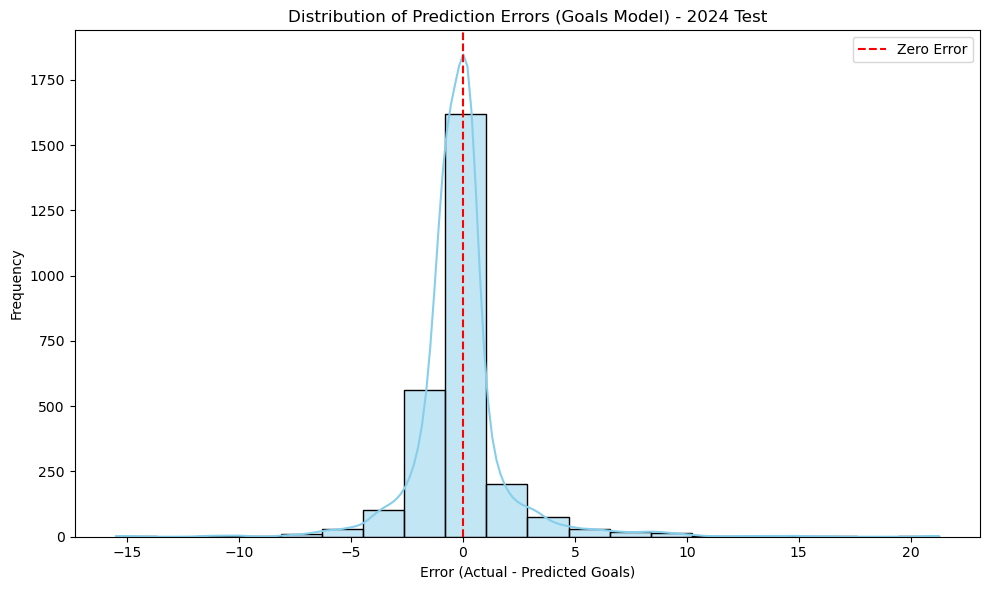

Goals Model MAE on 2024 Test Data: 1.21


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# Feature Importances Visualization
importances = {}
for name, model in models.items():
    if name == 'RF':
        raw_importance = model.named_steps['RF'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'XGBoost':
        raw_importance = model.named_steps['XGBoost'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'LightGBM':
        raw_importance = model.named_steps['LightGBM'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({'Feature': X_features.columns})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Normalize Ensemble_Importance to sum to 1
total_ensemble_importance = feature_importance['Ensemble_Importance'].sum()
feature_importance['Ensemble_Importance'] = feature_importance['Ensemble_Importance'] / total_ensemble_importance

# Top 10 Feature Importances
top_10_features = feature_importance.sort_values('Ensemble_Importance', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Feature Importances (Goals Model) - 2024 Test')
plt.xlabel('Normalized Ensemble Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('goals_feature_importances_2024.png')  # For slide 11
plt.show()

# Error Visualization (using 2024 test data)
errors_2024 = results_2024['Performance_Gls_next'] - results_2024['predicted_goals_2024']
plt.figure(figsize=(10, 6))
sns.histplot(errors_2024, bins=20, kde=True, color='skyblue')
plt.title('Distribution of Prediction Errors (Goals Model) - 2024 Test')
plt.xlabel('Error (Actual - Predicted Goals)')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--', label='Zero Error')
plt.legend()
plt.tight_layout()
plt.savefig('goals_error_distribution_2024.png')  # For slide 10
plt.show()

# Print MAE for reference (already calculated in your code, but re-verified)
mae_2024 = mean_absolute_error(results_2024['Performance_Gls_next'], results_2024['predicted_goals_2024'])
print(f"Goals Model MAE on 2024 Test Data: {mae_2024:.2f}")

<h1>Assists 2025</h1>

In [24]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Ast_next'] = data_full.groupby('player')['Performance_Ast'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Assist_Conversion_Rate'] = df['Performance_Ast'] / df['Expected_xA'].replace(0, 1)
    df['xA_Overperformance'] = df['Performance_Ast'] - df['Expected_xA']
    df['Ast_trend'] = df.groupby('player')['Performance_Ast'].pct_change().fillna(0)
    df['Ast_per_90'] = df['Performance_Ast'] / df['90s'].replace(0, 1)
    df['Ast_per_90_trend'] = df.groupby('player')['Ast_per_90'].pct_change().fillna(0)
    df['Recent_xA_Form'] = df.groupby('player')['Expected_xA'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Assist_Rate'] = (df['Performance_Ast'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Ast'] > 10).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Ast_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Ast_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_assists = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_assists)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop unnecessary features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Ast', 'Performance_Ast_next', 'league', 'team', 'Performance_Gls']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Ast_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Ast_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))

for name in models:
    print(f"{name} CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for model in models.values():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Ensemble predictions
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full.loc[data_full['season'] == 2024, 'predicted_assists_ensemble_2025_raw'] = np.maximum(ensemble_pred, 0)

# Apply boost/floor
actual_2025 = data_2025[['player', 'Performance_Ast']].set_index('player').to_dict()['Performance_Ast']
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025_raw']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_assists = actual_2025.get(player, 0)
    if row['Ast_per_90_trend'] > 0.3 and partial_assists > row['Performance_Ast'] * 0.5:
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] *= 1.5
    if partial_assists > row['Expected_xA']:
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] = max(data_full.loc[idx, 'predicted_assists_ensemble_2025'], partial_assists * 1.2)
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025'].clip(upper=20)

# Results
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Ast', 'Expected_xA', 'predicted_assists_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Ast', ascending=False).drop_duplicates('player', keep='last')
print("\n2025 Full-Season Assist Predictions:\n", all_players_2025)

# Validation
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))
scaling_factor = 1.5

# Raw MAE
raw_pred_vals = data_full.loc[data_full['season'] == 2024].set_index('player').loc[players_to_validate, 'predicted_assists_ensemble_2025_raw'].dropna().values
valid_players_raw = data_full.loc[data_full['season'] == 2024].set_index('player').loc[players_to_validate, 'predicted_assists_ensemble_2025_raw'].dropna().index
actual_vals_raw = [actual_2025[p] * scaling_factor for p in valid_players_raw]
print(f"\nRaw MAE: {mean_absolute_error(actual_vals_raw, raw_pred_vals):.2f}")

# Boosted MAE
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] * scaling_factor for p in valid_players_ensemble]
print(f"Boosted MAE: {mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals):.2f}")

# RMSE
print(f"Boosted RMSE: {np.sqrt(mean_squared_error(actual_vals_ensemble, ensemble_pred_vals)):.2f}")

# MAE by Position
print("\nMAE by Position (Boosted):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] * scaling_factor for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_assists_ensemble_2025'].values
        print(f"{pos} MAE: {mean_absolute_error(actual_vals, pred_vals):.2f} (n={len(pos_valid)})")

# Feature Importance
lgb_model = models['LightGBM'].named_steps['LightGBM']
lgb_importance = pd.DataFrame({'Feature': X_features.columns, 'Importance': lgb_model.feature_importances_})
print("\nLightGBM Feature Importance:\n", lgb_importance.sort_values('Importance', ascending=False).head(10))



[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007129 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27418
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 167
[LightGBM] [Info] Start training from score 1.372196
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [26]:
# Extract feature importances from individual models
importances = {}
for name, model in models.items():
    if name == 'RF':
        raw_importance = model.named_steps['RF'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'XGBoost':
        raw_importance = model.named_steps['XGBoost'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'LightGBM':
        raw_importance = model.named_steps['LightGBM'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({
    'Feature': X_features.columns
})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Normalize Ensemble_Importance to sum to 1
total_ensemble_importance = feature_importance['Ensemble_Importance'].sum()
feature_importance['Ensemble_Importance'] = feature_importance['Ensemble_Importance'] / total_ensemble_importance

# Sort by ensemble importance and get top 10
top_10_features = feature_importance.sort_values('Ensemble_Importance', ascending=False).head(10)

# Print top 10 features
print("\nTop 10 Features with Normalized Ensemble Importance:")
top_10_features[['Feature', 'Ensemble_Importance']]

# Optional: Save to CSV for presentation
#top_10_features[['Feature', 'Ensemble_Importance']].to_csv('top_10_assist_feature_importances.csv', index=False)

# Keep existing LightGBM importance print
#lgb_model = models['LightGBM'].named_steps['LightGBM']
#lgb_importance = pd.DataFrame({'Feature': X_features.columns, 'Importance': lgb_model.feature_importances_})
#print("\nLightGBM Feature Importance:\n", lgb_importance.sort_values('Importance', ascending=False).head(10))


Top 10 Features with Normalized Ensemble Importance:


,Feature,Ensemble_Importance
159,Recent_xA_Form,0.111420
135,Starts_Mn/Start,0.061887
86,GCA_GCA,0.049816
50,Medium_Cmp%,0.049245
164,Age,0.046928
42,Total_Cmp%,0.029108
78,SCA_SCA,0.025589
10,Expected_xAG,0.025366
56,Expected_xA,0.018436
11,Expected_npxG+xAG,0.017288


C:\Users\daboo\AppData\Local\Temp\ipykernel_23572\81549121.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')


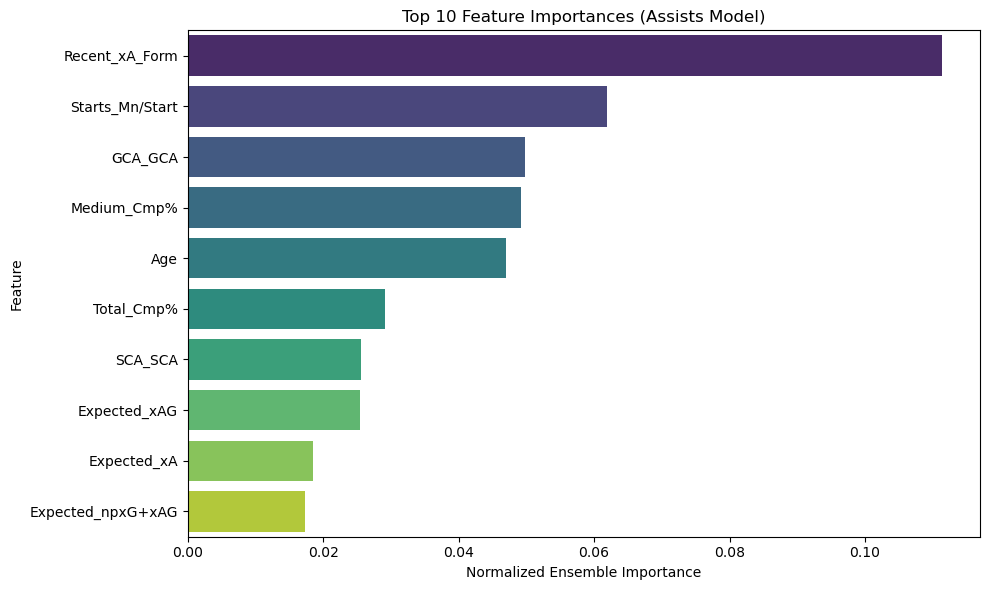

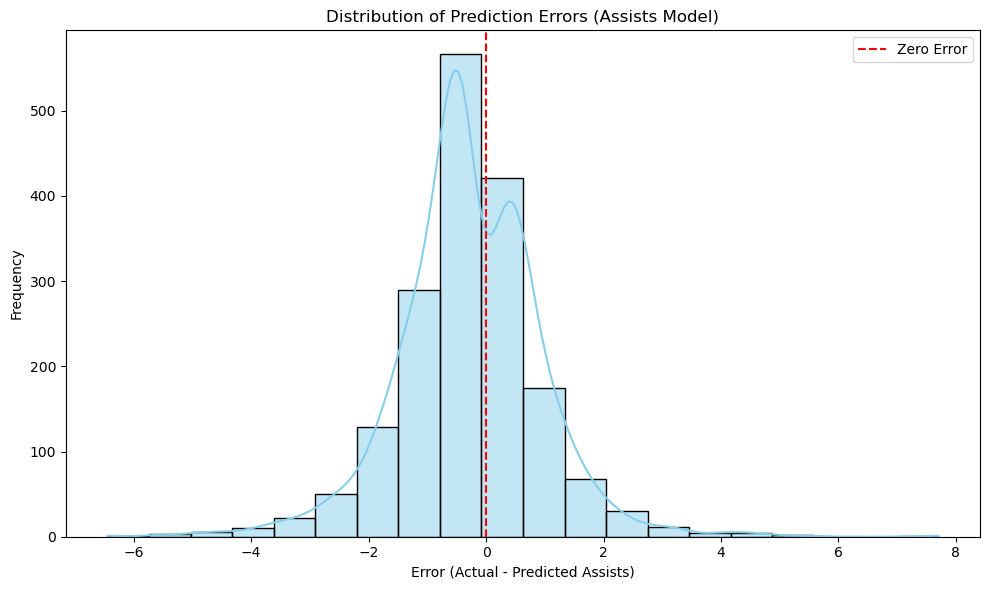

Assists Model MAE on 2025 Data: 0.95


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Assuming the Assists model code is run up to the ensemble prediction section
# Extract feature importances from individual models
importances = {}
for name, model in models.items():
    if name == 'RF':
        raw_importance = model.named_steps['RF'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'XGBoost':
        raw_importance = model.named_steps['XGBoost'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'LightGBM':
        raw_importance = model.named_steps['LightGBM'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({'Feature': X_features.columns})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Normalize Ensemble_Importance to sum to 1
total_ensemble_importance = feature_importance['Ensemble_Importance'].sum()
feature_importance['Ensemble_Importance'] = feature_importance['Ensemble_Importance'] / total_ensemble_importance

# Top 10 Feature Importances Visualization
top_10_features = feature_importance.sort_values('Ensemble_Importance', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Feature Importances (Assists Model)')
plt.xlabel('Normalized Ensemble Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('assists_feature_importances.png')  # Save for presentation slide 12
plt.show()

# Error Visualization (MAE Distribution)
# Assuming validation data from the code (actual vs. predicted for 2025)
pred_2025_df = data_full[data_full['season'] == 2024].set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] * scaling_factor for p in valid_players_ensemble]  # Apply scaling factor 1.5
errors = actual_vals_ensemble - ensemble_pred_vals

plt.figure(figsize=(10, 6))
sns.histplot(errors, bins=20, kde=True, color='skyblue')
plt.title('Distribution of Prediction Errors (Assists Model)')
plt.xlabel('Error (Actual - Predicted Assists)')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--', label='Zero Error')
plt.legend()
plt.tight_layout()
plt.savefig('assists_error_distribution.png')  # Save for presentation
plt.show()

# Print MAE for reference
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"Assists Model MAE on 2025 Data: {mae_ensemble:.2f}")

<h1>Assists 2024</h1>

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data (all positions)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')

# Add position dummies
data_full['is_FW'] = data_full['pos'].str.contains('FW', na=False).astype(int)
data_full['is_MF'] = data_full['pos'].str.contains('MF', na=False).astype(int)
data_full['is_DF'] = data_full['pos'].str.contains('DF', na=False).astype(int)

# Sort by player and season for lagging
data_full = data_full.sort_values(['player', 'season'])

# Create lagged target (next season's assists)
data_full['Performance_Ast_next'] = data_full.groupby('player')['Performance_Ast'].shift(-1)

# Feature Engineering (using current season data to predict next season)
# New assists model features
data_full['Assist_Conversion_Rate'] = data_full['Performance_Ast'] / data_full['Expected_xA'].replace(0, 1)
data_full['xA_Overperformance'] = data_full['Performance_Ast'] - data_full['Expected_xA']
data_full['Ast_trend'] = data_full.groupby('player')['Performance_Ast'].pct_change().fillna(0)
data_full['Ast_per_90'] = data_full['Performance_Ast'] / data_full['90s'].replace(0, 1)
data_full['Ast_per_90_trend'] = data_full.groupby('player')['Ast_per_90'].pct_change().fillna(0)
data_full['Recent_xA_Form'] = data_full.groupby('player')['Expected_xA'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Assist_Rate'] = (data_full['Performance_Ast'] / data_full['90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Ast'] > 10).astype(int))
data_full['Minutes_per_90'] = data_full['Playing Time_Min'] / 90
data_full['Minutes_per_90_trend'] = data_full.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
data_full['Breakout_Signal'] = data_full['Ast_per_90_trend'] * data_full['Minutes_per_90_trend'] * data_full['Team Success_onG']
data_full.loc[data_full['season'] == 2023, 'Ast_per_90_trend'] *= 2.0
data_full.loc[data_full['season'] == 2023, 'Breakout_Signal'] *= 10.0

# General features
data_full['Age'] = 2024 - data_full['born']  # Age as of 2024
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)
league_avg_assists = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_assists)

# Handle missing values
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(data_full.median(numeric_only=True), inplace=True)

# Drop irrelevant features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define feature set (exclude current-season assists and metadata)
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Ast', 'Performance_Ast_next', 'league', 'team', 'Performance_Gls']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Debug: Ensure Performance_Ast is not in X_features
if 'Performance_Ast' in X_features.columns:
    raise ValueError("Performance_Ast is still in X_features!")

# Split data: Train on 2019–2022, Test on 2023 to predict 2024
train_data = data_full[data_full['season'].isin([2019, 2020, 2021, 2022])].dropna(subset=['Performance_Ast_next'] + list(X_features.columns))
test_data = data_full[data_full['season'] == 2023].dropna(subset=['Performance_Ast_next'] + list(X_features.columns))

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Ast_next']
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Ast_next']

# Weighted training (similar to old model, adjusted for years)
train_weighted_parts = [
    train_data[train_data['season'].isin([2019, 2020])],
    train_data[train_data['season'] == 2021].sample(frac=2, replace=True, random_state=42) if not train_data[train_data['season'] == 2021].empty else pd.DataFrame(),
    train_data[train_data['season'] == 2022].sample(frac=2, replace=True, random_state=42) if not train_data[train_data['season'] == 2022].empty else pd.DataFrame()
]
train_weighted = pd.concat(train_weighted_parts, ignore_index=True)

X_train_weighted = train_weighted[X_features.columns]
y_train_weighted = train_weighted['Performance_Ast_next']

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train_weighted):
    X_tr, X_val = X_train_weighted.iloc[train_idx], X_train_weighted.iloc[val_idx]
    y_tr, y_val = y_train_weighted.iloc[train_idx], y_train_weighted.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train_weighted, y_train_weighted)

# Predict on 2024 test set (using 2023 data)
individual_preds = {name: np.maximum(model.predict(X_test), 0) for name, model in models.items()}

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
ensemble_pred = np.maximum(ensemble_pred, 0)

# Calculate MAE and R-squared for 2024
mae_2024 = mean_absolute_error(y_test, ensemble_pred)
r2_2024 = r2_score(y_test, ensemble_pred)

# Print results
print("\nAssist Model (2024 Full Season) - Ensemble Results:")
print(f"MAE: {mae_2024:.2f}")
print(f"R²: {r2_2024:.2f}")

# Results table for inspection
results_2024 = test_data[['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 'Performance_Ast', 'Performance_Ast_next']].copy()
results_2024['predicted_assists_2024'] = ensemble_pred
print("\n2024 Full-Season Assist Predictions (Sample):")
print(results_2024.sort_values('Performance_Ast_next', ascending=False).head(10))

# MAE and R² by Position (2024 Test Set)
print("\nMAE and R² by Position (2024 Test Set):")
for pos in ['FW', 'MF', 'DF']:
    pos_mask = results_2024[f'is_{pos}'] == 1
    if pos_mask.sum() > 0:
        actual_pos = results_2024[pos_mask]['Performance_Ast_next']
        pred_pos = results_2024[pos_mask]['predicted_assists_2024']
        mae_pos = mean_absolute_error(actual_pos, pred_pos)
        r2_pos = r2_score(actual_pos, pred_pos)
        print(f"{pos} - MAE: {mae_pos:.2f}, R²: {r2_pos:.2f}, n={pos_mask.sum()}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006299 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 22804
[LightGBM] [Info] Number of data points in the train set: 8775, number of used features: 167
[LightGBM] [Info] Start training from score 1.382336
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

C:\Users\daboo\AppData\Local\Temp\ipykernel_18768\2083631476.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')


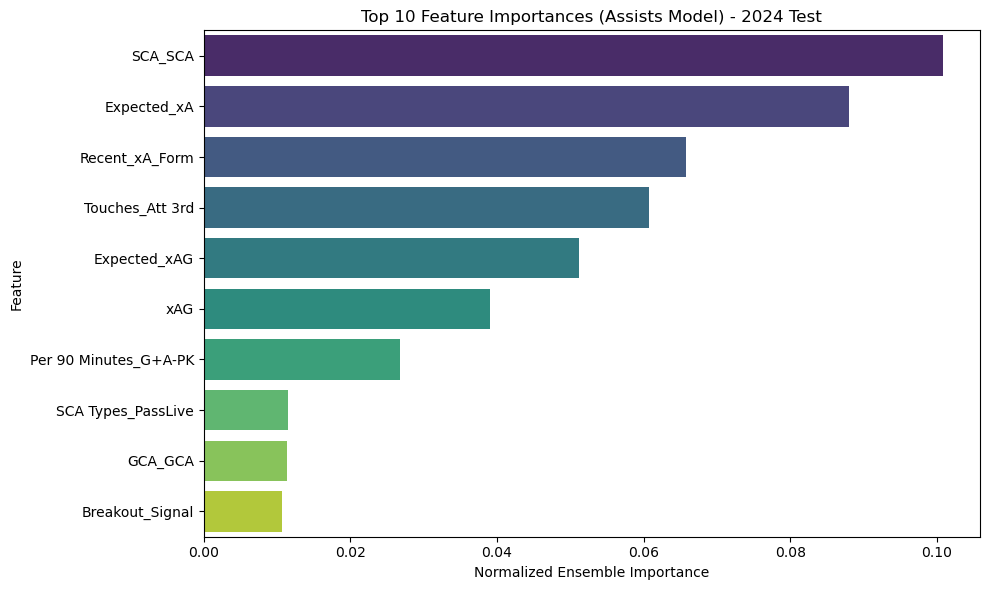

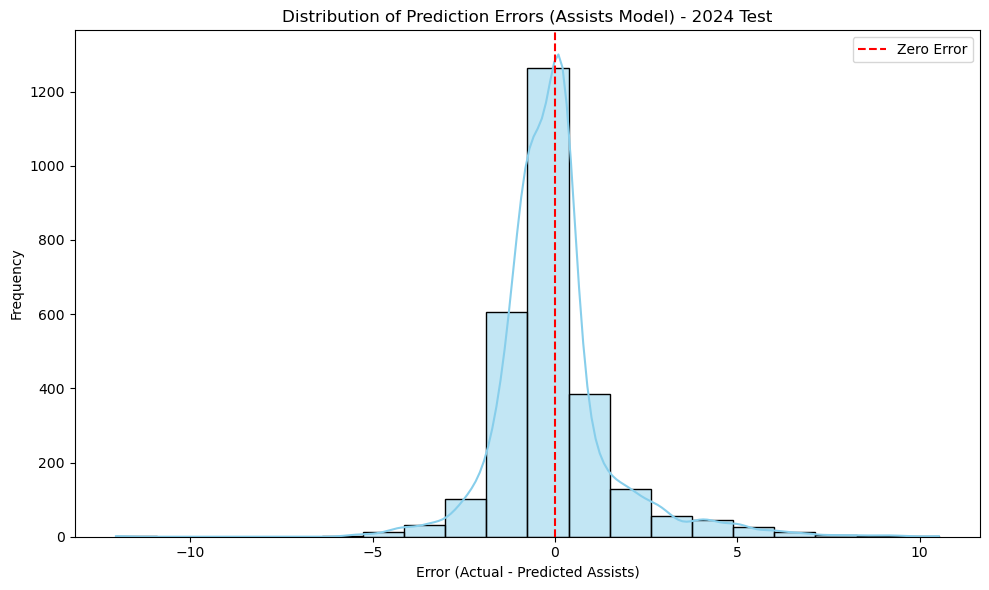

Assists Model MAE on 2024 Test Data: 1.00


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# Feature Importances Visualization
importances = {}
for name, model in models.items():
    if name == 'RF':
        raw_importance = model.named_steps['RF'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'XGBoost':
        raw_importance = model.named_steps['XGBoost'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1
    elif name == 'LightGBM':
        raw_importance = model.named_steps['LightGBM'].feature_importances_
        importances[name] = raw_importance / raw_importance.sum()  # Normalize to sum to 1

# Combine importances with ensemble weights
feature_importance = pd.DataFrame({'Feature': X_features.columns})
for name, imp in importances.items():
    feature_importance[f'{name}_Importance'] = imp
feature_importance['Ensemble_Importance'] = (weights['RF'] * feature_importance['RF_Importance'] +
                                           weights['XGBoost'] * feature_importance['XGBoost_Importance'] +
                                           weights['LightGBM'] * feature_importance['LightGBM_Importance'])

# Normalize Ensemble_Importance to sum to 1
total_ensemble_importance = feature_importance['Ensemble_Importance'].sum()
feature_importance['Ensemble_Importance'] = feature_importance['Ensemble_Importance'] / total_ensemble_importance

# Top 10 Feature Importances
top_10_features = feature_importance.sort_values('Ensemble_Importance', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x='Ensemble_Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Feature Importances (Assists Model) - 2024 Test')
plt.xlabel('Normalized Ensemble Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('assists_feature_importances_2024.png')  # For slide 12
plt.show()

# Error Visualization (using 2024 test data)
errors_2024 = results_2024['Performance_Ast_next'] - results_2024['predicted_assists_2024']
plt.figure(figsize=(10, 6))
sns.histplot(errors_2024, bins=20, kde=True, color='skyblue')
plt.title('Distribution of Prediction Errors (Assists Model) - 2024 Test')
plt.xlabel('Error (Actual - Predicted Assists)')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--', label='Zero Error')
plt.legend()
plt.tight_layout()
plt.savefig('assists_error_distribution_2024.png')  # For slide 10
plt.show()

# Print MAE for reference (already calculated in your code, but re-verified)
mae_2024 = mean_absolute_error(results_2024['Performance_Ast_next'], results_2024['predicted_assists_2024'])
print(f"Assists Model MAE on 2024 Test Data: {mae_2024:.2f}")